# PyTorch / Jupyter 环境自检

按顺序运行下面的格子。全部成功即可用于后续 Computer Vision 和 Deep Learning 作业。

请用 **Run Cell**（不要用 Debug Cell），避免调试器把第一次 `import torch` 卡住。

In [3]:
import sys
import platform

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torchvision
from torchvision import transforms

print("Python:", sys.version.split()[0], platform.machine())
print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Jupyter: OK")

Matplotlib is building the font cache; this may take a moment.


Python: 3.10.21 arm64
NumPy: 2.2.6
PyTorch: 2.14.0
Torchvision: 0.29.0
Jupyter: OK


In [5]:
if torch.backends.mps.is_available():
    device = torch.device("mps")
    accel = "Apple Silicon MPS"
elif torch.cuda.is_available():
    device = torch.device("cuda")
    accel = "CUDA"
else:
    device = torch.device("cpu")
    accel = "CPU only"

print("Device:", device, f"({accel})")

x = torch.randn(4, 3, device=device)
y = torch.randn(3, 2, device=device)
z = x @ y
print("Matmul shape:", tuple(z.shape))
print("Tensor test: OK")

Device: mps (Apple Silicon MPS)
Matmul shape: (4, 2)
Tensor test: OK


In [7]:
torch.manual_seed(0)

model = nn.Sequential(
    nn.Linear(2, 16),
    nn.ReLU(),
    nn.Linear(16, 1),
).to(device)
opt = torch.optim.Adam(model.parameters(), lr=0.05)
loss_fn = nn.MSELoss()

X = torch.randn(64, 2, device=device)
y = (X[:, 0] + 0.5 * X[:, 1]).unsqueeze(1)

for _ in range(80):
    pred = model(X)
    loss = loss_fn(pred, y)
    opt.zero_grad()
    loss.backward()
    opt.step()

print(f"Final loss: {loss.item():.4f}")
print("Train test: OK")

Final loss: 0.0004
Train test: OK


Image tensor: (3, 32, 32) torch.float32


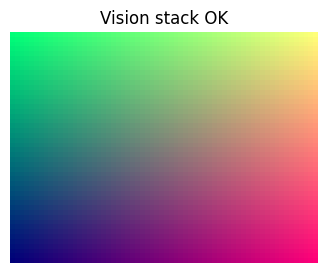

Computer vision test: OK


In [8]:
img = Image.fromarray(
    np.stack(
        [
            np.linspace(0, 255, 64, dtype=np.uint8)[None, :].repeat(48, axis=0),
            np.linspace(255, 0, 48, dtype=np.uint8)[:, None].repeat(64, axis=1),
            np.full((48, 64), 120, dtype=np.uint8),
        ],
        axis=-1,
    )
)

tfm = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])
tensor = tfm(img)
print("Image tensor:", tuple(tensor.shape), tensor.dtype)

plt.figure(figsize=(4, 3))
plt.imshow(img)
plt.axis("off")
plt.title("Vision stack OK")
plt.show()
print("Computer vision test: OK")